In [40]:
#import libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
df=pd.read_csv("/content/Shoppers_Behaviour_and_Revenue.csv")


In [42]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [43]:
df.tail()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False


In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [45]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [46]:
df.duplicated().sum()

np.int64(125)

In [47]:
df.drop_duplicates(inplace=True)

In [48]:
df.duplicated().sum()

np.int64(0)

In [49]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [50]:
df = pd.get_dummies(df, columns=['Revenue'], drop_first=True, dtype=int)

In [51]:
#Outlier treatment
num_cols=df.select_dtypes(include=np.number).columns.drop("Revenue", errors='ignore')
print(num_cols)

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Revenue_True'],
      dtype='object')


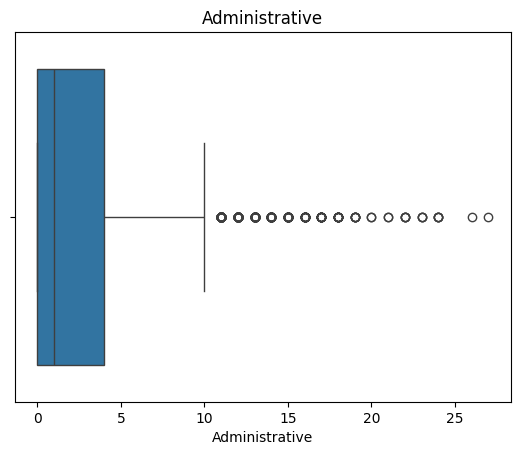

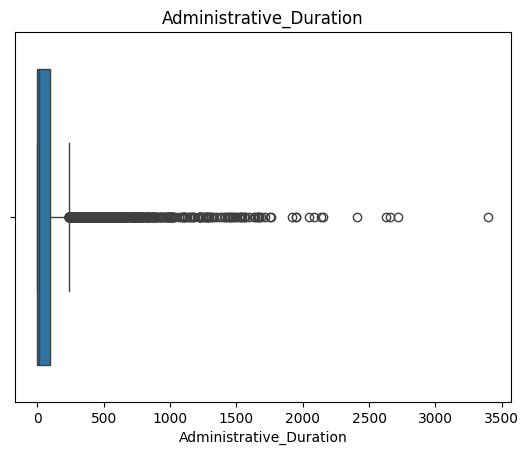

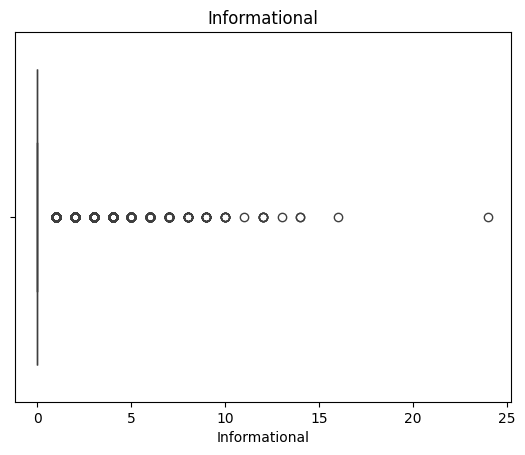

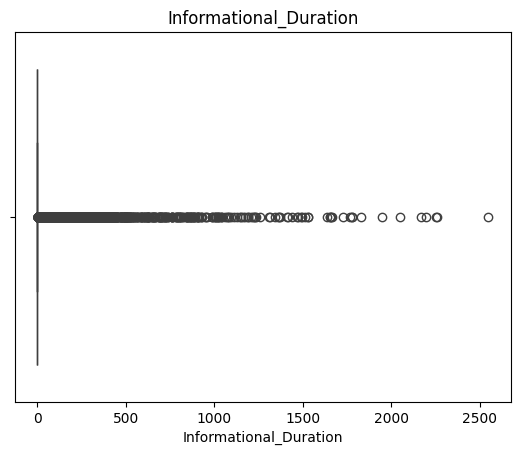

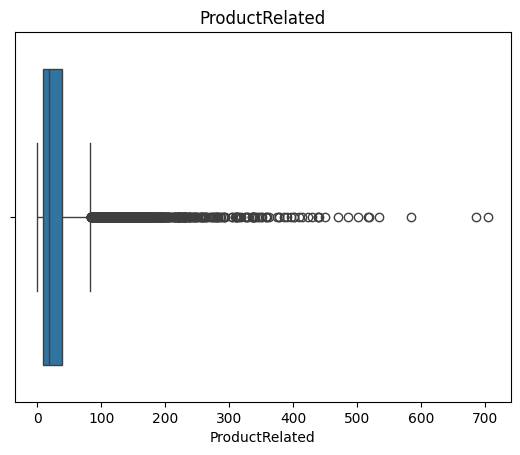

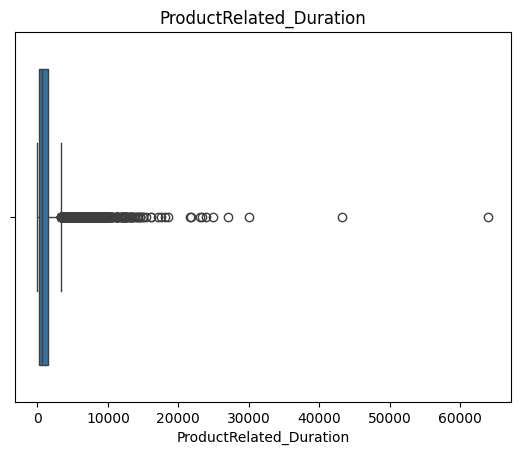

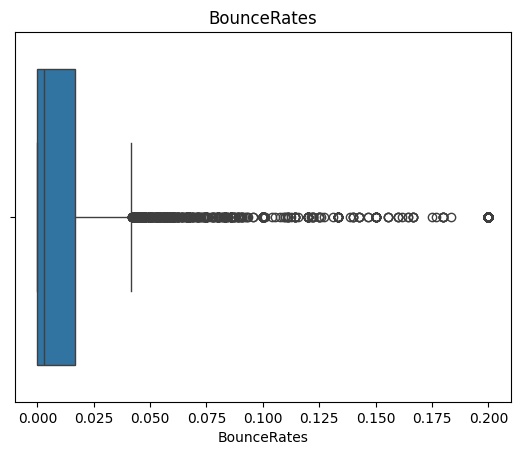

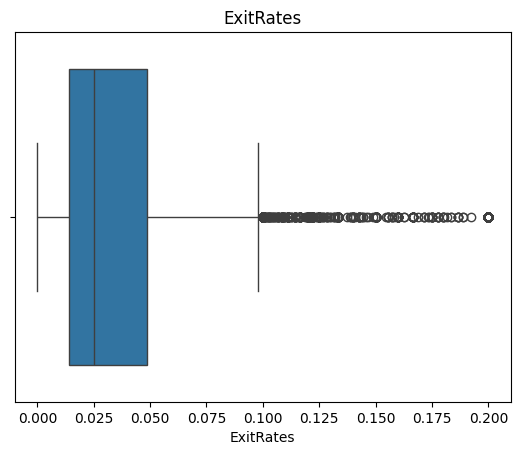

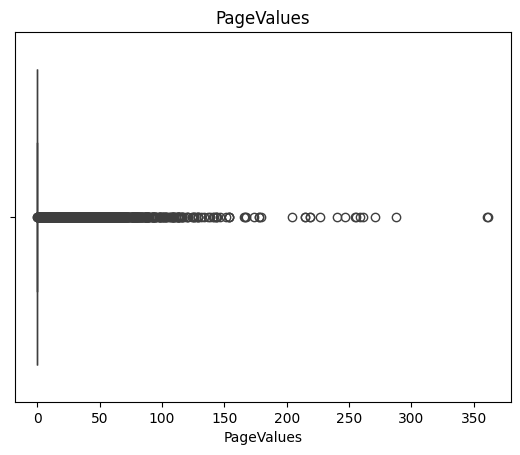

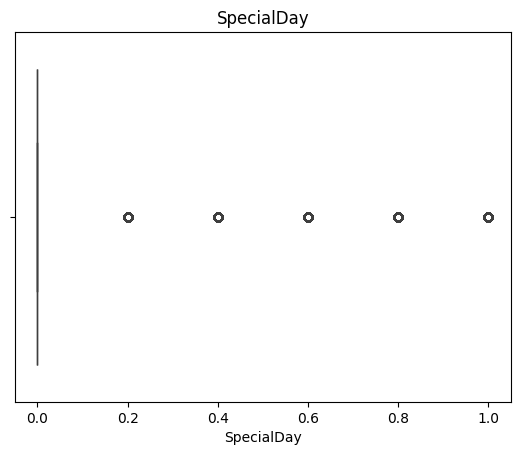

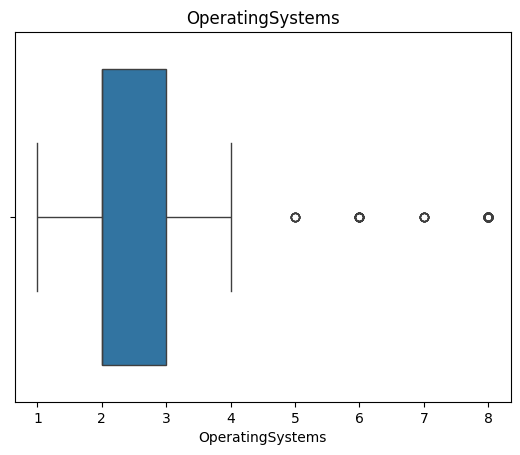

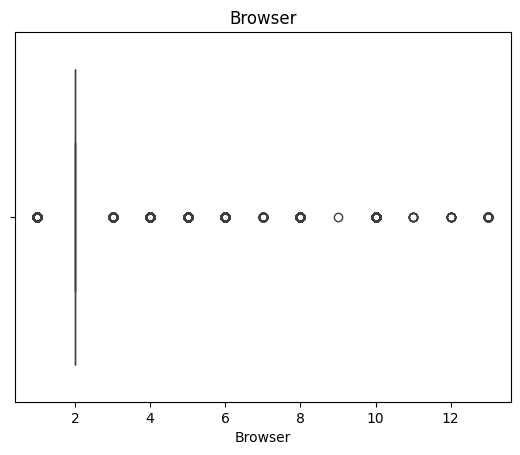

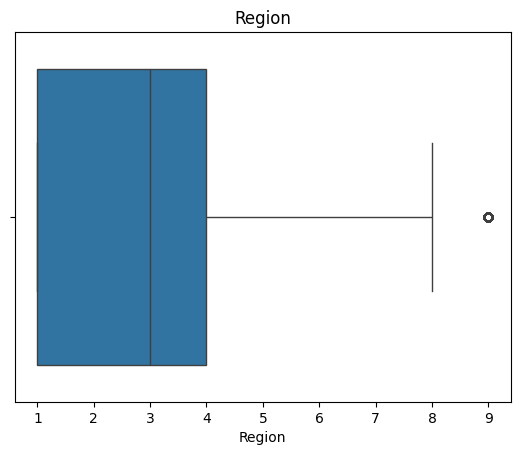

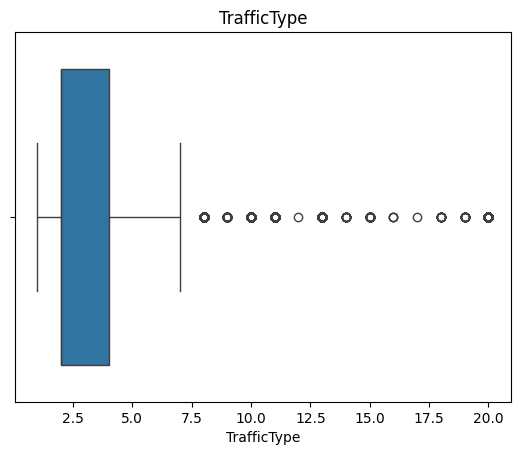

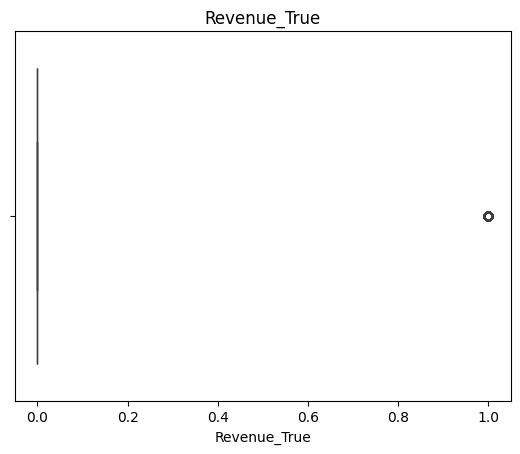

In [52]:
for col in df.select_dtypes(include = 'number').columns:

  sns.boxplot(x = df[col])

  plt.title(col)

  plt.show()

In [53]:
#Outlier treatment for numerical columns with outliers
num_cols = ['PageValues', 'TrafficType', 'Browser', 'ExitRates']

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower_bound, upper_bound)


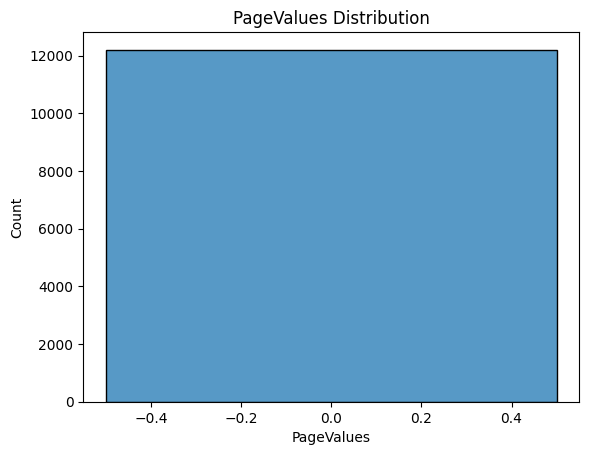

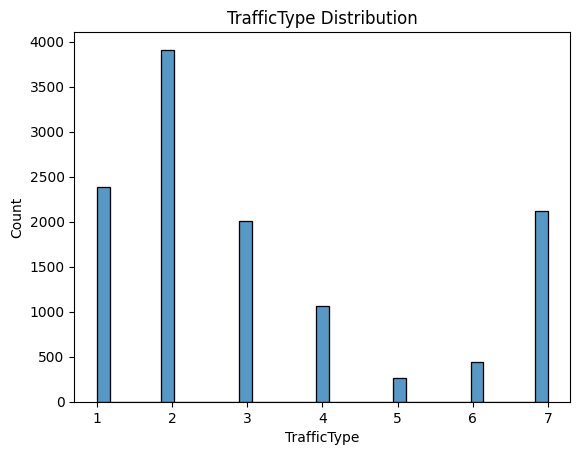

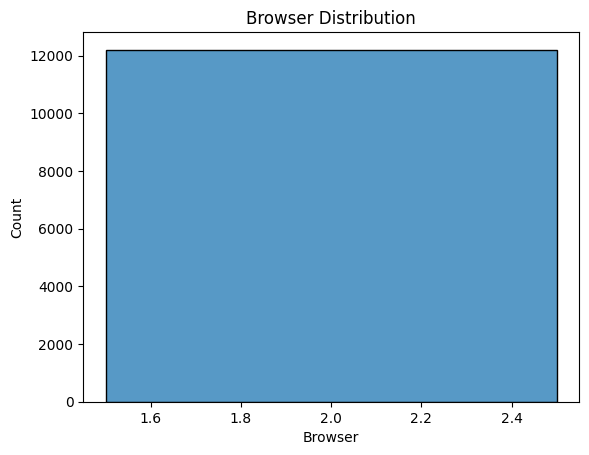

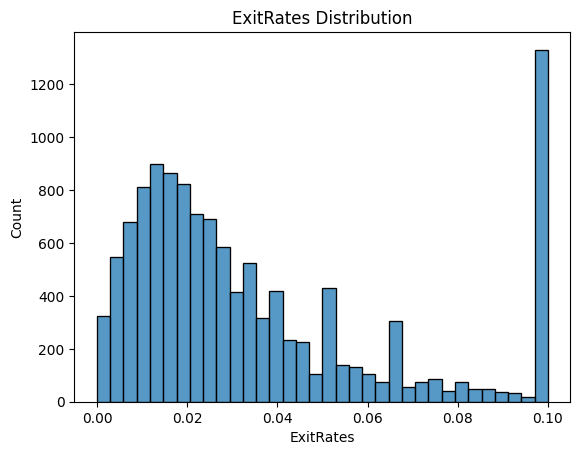

In [54]:
#univareant analysis
for col in num_cols:
    sns.histplot(x=df[col])
    plt.title(f'{col} Distribution')
    plt.show()

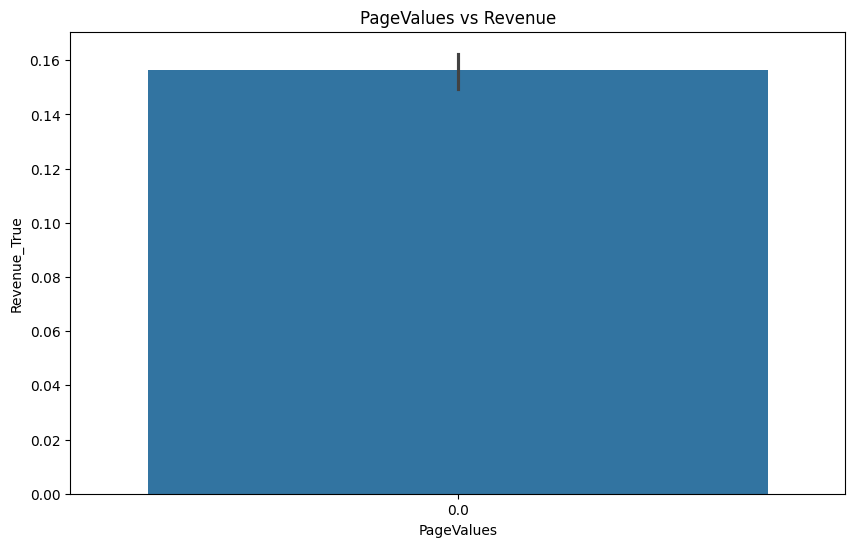

In [55]:
#bivareant analysis
plt.figure(figsize=(10, 6))
sns.barplot(x='PageValues', y='Revenue_True', data=df)
plt.title('PageValues vs Revenue')
plt.show()

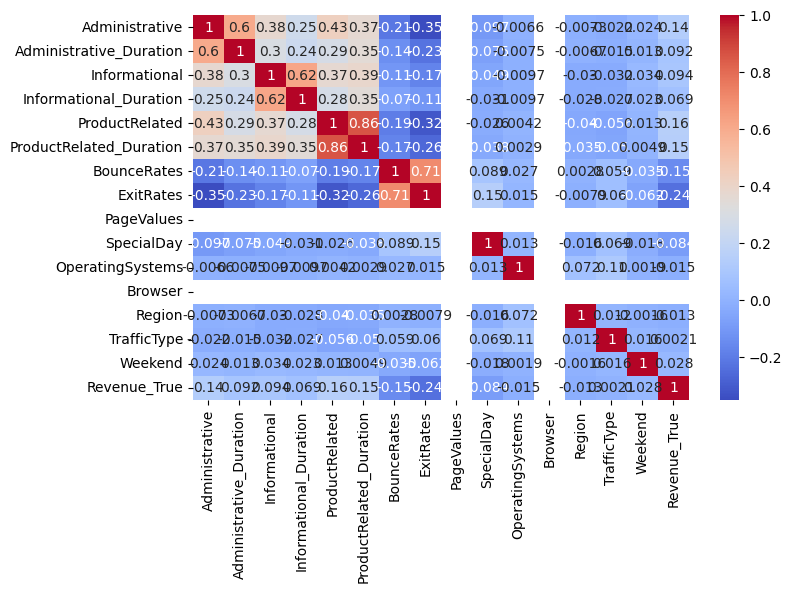

In [56]:
#multivariant ananlysis
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(numeric_only = True), annot = True,cmap = 'coolwarm')
plt.show()

In [57]:
#converting objective to numerical data types
cat_cols=df.select_dtypes(exclude=np.number).columns
print(cat_cols)

Index(['Month', 'VisitorType', 'Weekend'], dtype='object')


In [58]:
for col in cat_cols:
    print(col,df[col].unique())

Month ['Feb' 'Mar' 'May' 'Oct' 'June' 'Jul' 'Aug' 'Nov' 'Sep' 'Dec']
VisitorType ['Returning_Visitor' 'New_Visitor' 'Other']
Weekend [False  True]


In [59]:
# converting
df=pd.get_dummies(df,columns=cat_cols,drop_first=True,dtype=int)
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor,Weekend_True
0,0,0.0,0,0.0,1,0.000000,0.20,0.099977,0.0,0.0,...,0,0,0,0,0,0,0,0,1,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.099977,0.0,0.0,...,0,0,0,0,0,0,0,0,1,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.099977,0.0,0.0,...,0,0,0,0,0,0,0,0,1,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.099977,0.0,0.0,...,0,0,0,0,0,0,0,0,1,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.050000,0.0,0.0,...,0,0,0,0,0,0,0,0,1,1


In [60]:
#divide the data set in to x andy variables
x=df.drop(columns=['Revenue_True'])
y=df['Revenue_True']

In [61]:
print(x.shape)
print(y.shape)

(12205, 26)
(12205,)


In [62]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [63]:
#model
from sklearn.ensemble import AdaBoostClassifier,RandomForestClassifier,GradientBoostingClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [64]:
model=AdaBoostClassifier(
    n_estimators=100,
    random_state=42,
    learning_rate=1.0
    )

In [65]:
model.fit(x_train,y_train)

AdaBoostClassifier(n_estimators=100, random_state=42)

In [66]:
Y_pred=model.predict(x_test)
print(Y_pred)

[0 0 0 ... 0 0 0]


In [67]:
#python
print("training accuracy:",model.score(x_train,y_train))
print("testing accuracy",model.score(x_test,y_test))

training accuracy: 0.8423801720606309
testing accuracy 0.8521097910692339


In [68]:
#classifier
print(classification_report(y_test,Y_pred))

              precision    recall  f1-score   support

           0       0.85      1.00      0.92      2079
           1       0.53      0.02      0.04       362

    accuracy                           0.85      2441
   macro avg       0.69      0.51      0.48      2441
weighted avg       0.81      0.85      0.79      2441



In [69]:
rf=RandomForestClassifier(n_estimators=100,random_state=42)
rf.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [70]:
print("training accuracy:",rf.score(x_train,y_train))
print("testing accuracy",rf.score(x_test,y_test))

training accuracy: 0.9998975829578042
testing accuracy 0.8512904547316673


In [ ]:
#hyperparameter tuning
from sklearn.model_selection import GridSearchCV
param_grid = {
         'n_estimators': [50, 100, 200],
         'max_depth': [None, 10, 20, 30],
         'min_samples_split': [2, 5, 10],
         'min_samples_leaf': [1, 2, 4]
         }
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(x_train, y_train)

In [ ]:
print("training accuracy:",grid_search.score(x_train,y_train) )
print("testing accuracy:",grid_search.score(x_test,y_test) )